
[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


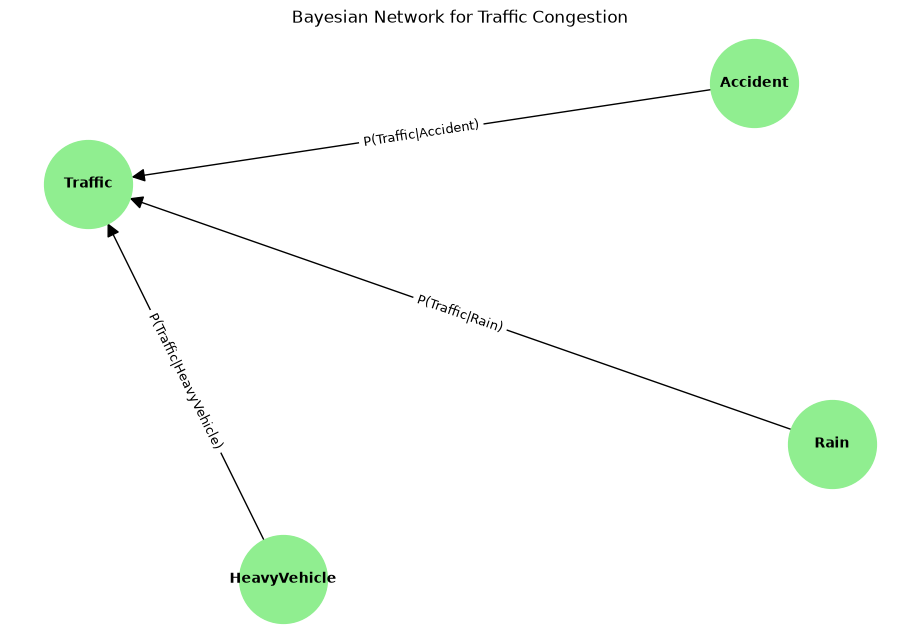

Is the Bayesian network valid? True

CPD of Rain:
 +---------+-----+
| Rain(0) | 0.2 |
+---------+-----+
| Rain(1) | 0.8 |
+---------+-----+

CPD of Accident:
 +-------------+------+
| Accident(0) | 0.95 |
+-------------+------+
| Accident(1) | 0.05 |
+-------------+------+

CPD of Heavy Vehicle:
 +-----------------+------+
| HeavyVehicle(0) | 0.25 |
+-----------------+------+
| HeavyVehicle(1) | 0.75 |
+-----------------+------+

CPD of Traffic:
 +--------------+-----------------+-----+-----------------+
| Rain         | Rain(0)         | ... | Rain(1)         |
+--------------+-----------------+-----+-----------------+
| Accident     | Accident(0)     | ... | Accident(1)     |
+--------------+-----------------+-----+-----------------+
| HeavyVehicle | HeavyVehicle(0) | ... | HeavyVehicle(1) |
+--------------+-----------------+-----+-----------------+
| Traffic(0)   | 0.9             | ... | 0.05            |
+--------------+-----------------+-----+-----------------+
| Traffic(1)   | 

In [ ]:
!pip install pgmpy networkx matplotlib
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
import networkx as nx
import matplotlib.pyplot as plt

nodes = ["Rain", "Accident", "HeavyVehicle", "Traffic"]

edges = [
    ("Rain", "Traffic"),
    ("Accident", "Traffic"),
    ("HeavyVehicle", "Traffic")
]

network = DiscreteBayesianNetwork(edges)

graph = nx.DiGraph()
graph.add_nodes_from(nodes)
graph.add_edges_from(edges)

pos = nx.spring_layout(graph, seed=10)

plt.figure(figsize=(9, 6))
nx.draw(
    graph, pos,
    with_labels=True,
    node_size=4000,
    node_color="lightgreen",
    font_size=10,
    font_weight="bold",
    arrowsize=20
)

edge_labels = {
    ("Rain", "Traffic"): "P(Traffic|Rain)",
    ("Accident", "Traffic"): "P(Traffic|Accident)",
    ("HeavyVehicle", "Traffic"): "P(Traffic|HeavyVehicle)"
}

nx.draw_networkx_edge_labels(
    graph, pos,
    edge_labels=edge_labels,
    font_size=9
)

plt.title("Bayesian Network for Traffic Congestion")
plt.show()

cpd_rain = TabularCPD("Rain",2,[[0.20], [0.80]])

cpd_accident = TabularCPD("Accident",2,[[0.95], [0.05]])

cpd_heavy_vehicle = TabularCPD("HeavyVehicle",2,[[0.25], [0.75]]
)

cpd_traffic = TabularCPD("Traffic",2,[
        [0.90, 0.70, 0.60, 0.40,
         0.50, 0.30, 0.20, 0.05],
        [0.10, 0.30, 0.40, 0.60,
         0.50, 0.70, 0.80, 0.95]
    ],
    evidence=["Rain", "Accident", "HeavyVehicle"],
    evidence_card=[2, 2, 2]
)

network.add_cpds(
    cpd_rain,
    cpd_accident,
    cpd_heavy_vehicle,
    cpd_traffic
)

print("Is the Bayesian network valid?", network.check_model())

print("\nCPD of Rain:\n", cpd_rain)
print("\nCPD of Accident:\n", cpd_accident)
print("\nCPD of Heavy Vehicle:\n", cpd_heavy_vehicle)
print("\nCPD of Traffic:\n", cpd_traffic)

p_rain = cpd_rain.values[1]
p_not_accident = cpd_accident.values[0]
p_heavy_vehicle = cpd_heavy_vehicle.values[1]
p_traffic = cpd_traffic.values[1, 1, 0, 1]

joint_probability = (
    p_rain
    * p_not_accident
    * p_heavy_vehicle
    * p_traffic
)

print("\nRequired Probability:")
print(
    "P(Rain=True, Accident=False, HeavyVehicle=True, Traffic=True) =",
    joint_probability
)

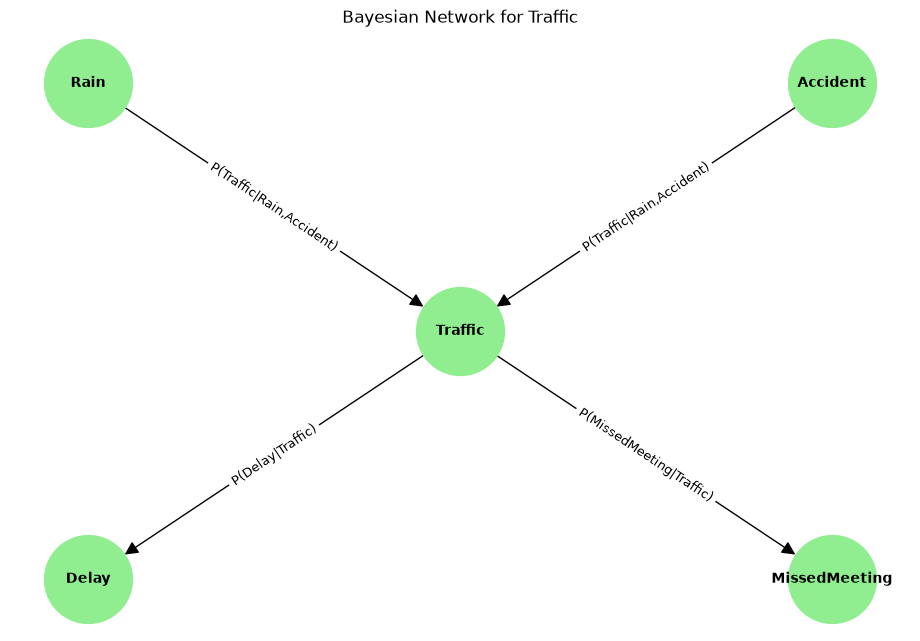

Is Bayesian Network valid? True

CPD of Rain:
 +---------+-----+
| Rain(0) | 0.8 |
+---------+-----+
| Rain(1) | 0.2 |
+---------+-----+

CPD of Accident:
 +-------------+------+
| Accident(0) | 0.95 |
+-------------+------+
| Accident(1) | 0.05 |
+-------------+------+

CPD of Traffic:
 +------------+-------------+-------------+-------------+-------------+
| Rain       | Rain(0)     | Rain(0)     | Rain(1)     | Rain(1)     |
+------------+-------------+-------------+-------------+-------------+
| Accident   | Accident(0) | Accident(1) | Accident(0) | Accident(1) |
+------------+-------------+-------------+-------------+-------------+
| Traffic(0) | 0.95        | 0.4         | 0.3         | 0.05        |
+------------+-------------+-------------+-------------+-------------+
| Traffic(1) | 0.05        | 0.6         | 0.7         | 0.95        |
+------------+-------------+-------------+-------------+-------------+

CPD of Delay:
 +----------+------------+------------+
| Traffic  | Traf

In [ ]:
# %pip install pgmpy networkx matplotlib

from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
import networkx as nx
import matplotlib.pyplot as plt
nodes = ["Rain", "Accident", "Traffic", "Delay", "MissedMeeting"]


edges = [
    ("Rain", "Traffic"),
    ("Accident", "Traffic"),
    ("Traffic", "Delay"),
    ("Traffic", "MissedMeeting")
]

network = DiscreteBayesianNetwork(edges)
graph = nx.DiGraph()
graph.add_nodes_from(nodes)
graph.add_edges_from(edges)

pos = {
    "Rain": (0, 2),
    "Accident": (2, 2),
    "Traffic": (1, 1),
    "Delay": (0, 0),
    "MissedMeeting": (2, 0)
}

plt.figure(figsize=(9, 6))

nx.draw(
    graph, pos,
    with_labels=True,
    node_size=4000,
    node_color="lightgreen",
    font_size=10,
    font_weight="bold",
    arrowsize=20
)

edge_labels = {
    ("Rain", "Traffic"): "P(Traffic|Rain,Accident)",
    ("Accident", "Traffic"): "P(Traffic|Rain,Accident)",
    ("Traffic", "Delay"): "P(Delay|Traffic)",
    ("Traffic", "MissedMeeting"): "P(MissedMeeting|Traffic)"
}

nx.draw_networkx_edge_labels(
    graph, pos,
    edge_labels=edge_labels,
    font_size=9
)


plt.title("Bayesian Network for Traffic")
plt.show()


cpd_rain = TabularCPD(
    "Rain", 2,
    [[0.80], [0.20]]
)

cpd_accident = TabularCPD(
    "Accident", 2,
    [[0.95], [0.05]]
)

cpd_traffic = TabularCPD(
    "Traffic", 2,
    [
        [0.95, 0.40, 0.30, 0.05],
        [0.05, 0.60, 0.70, 0.95]
    ],
    evidence=["Rain", "Accident"],
    evidence_card=[2, 2]
)

cpd_delay = TabularCPD(
    "Delay", 2,
    [
        [0.90, 0.20],
        [0.10, 0.80]
    ],
    evidence=["Traffic"],
    evidence_card=[2]
)

cpd_missed = TabularCPD(
    "MissedMeeting", 2,
    [
        [0.95, 0.30],
        [0.05, 0.70]
    ],
    evidence=["Traffic"],
    evidence_card=[2]
)

network.add_cpds(
    cpd_rain,
    cpd_accident,
    cpd_traffic,
    cpd_delay,
    cpd_missed
)

print("Is Bayesian Network valid?", network.check_model())

print("\nCPD of Rain:\n", cpd_rain)
print("\nCPD of Accident:\n", cpd_accident)
print("\nCPD of Traffic:\n", cpd_traffic)
print("\nCPD of Delay:\n", cpd_delay)
print("\nCPD of MissedMeeting:\n", cpd_missed)

p_rain = cpd_rain.values[1]
p_accident = cpd_accident.values[0]
p_traffic = cpd_traffic.values[1, 1, 0]

p_delay = cpd_delay.values[1, 1]
p_missed = cpd_missed.values[1, 1]

joint_probability = (
    p_rain
    * p_accident
    * p_traffic
    * p_delay
    * p_missed
)

print("\nRequired Joint Probability:")

print(
    "P(Rain=True, Accident=False, Traffic=True, "
    "Delay=True, MissedMeeting=True) =",
    joint_probability
)

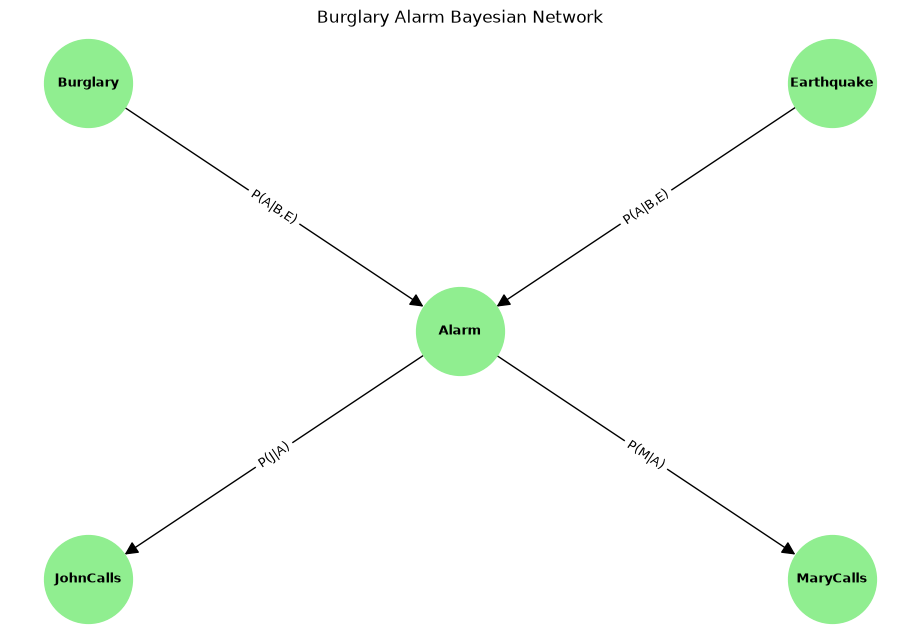

Network valid: True

CPD Burglary:
 +-------------+-------+
| Burglary(0) | 0.999 |
+-------------+-------+
| Burglary(1) | 0.001 |
+-------------+-------+

CPD Earthquake:
 +---------------+-------+
| Earthquake(0) | 0.998 |
+---------------+-------+
| Earthquake(1) | 0.002 |
+---------------+-------+

CPD Alarm:
 +------------+---------------+---------------+---------------+---------------+
| Burglary   | Burglary(0)   | Burglary(0)   | Burglary(1)   | Burglary(1)   |
+------------+---------------+---------------+---------------+---------------+
| Earthquake | Earthquake(0) | Earthquake(1) | Earthquake(0) | Earthquake(1) |
+------------+---------------+---------------+---------------+---------------+
| Alarm(0)   | 0.999         | 0.71          | 0.06          | 0.05          |
+------------+---------------+---------------+---------------+---------------+
| Alarm(1)   | 0.001         | 0.29          | 0.94          | 0.95          |
+------------+---------------+---------------+-----

In [ ]:

# %pip install pgmpy networkx matplotlib

from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
import networkx as nx
import matplotlib.pyplot as plt
nodes = ["Burglary", "Earthquake", "Alarm",
         "JohnCalls", "MaryCalls"]

edges = [
    ("Burglary", "Alarm"),
    ("Earthquake", "Alarm"),
    ("Alarm", "JohnCalls"),
    ("Alarm", "MaryCalls")
]


network = DiscreteBayesianNetwork(edges)
graph = nx.DiGraph()
graph.add_nodes_from(nodes)
graph.add_edges_from(edges)

pos = {
    "Burglary": (0, 2),
    "Earthquake": (2, 2),
    "Alarm": (1, 1),
    "JohnCalls": (0, 0),
    "MaryCalls": (2, 0)
}

plt.figure(figsize=(9, 6))

nx.draw(
    graph, pos,
    with_labels=True,
    node_size=4000,
    node_color="lightgreen",
    font_size=9,
    font_weight="bold",
    arrowsize=20
)

# 5. Edge Labels
edge_labels = {
    ("Burglary", "Alarm"): "P(A|B,E)",
    ("Earthquake", "Alarm"): "P(A|B,E)",
    ("Alarm", "JohnCalls"): "P(J|A)",
    ("Alarm", "MaryCalls"): "P(M|A)"
}

nx.draw_networkx_edge_labels(
    graph, pos,
    edge_labels=edge_labels,
    font_size=9
)

plt.title("Burglary Alarm Bayesian Network")
plt.show()

# 6. CPDs

cpd_b = TabularCPD(
    "Burglary", 2,
    [[0.999], [0.001]]
)

cpd_e = TabularCPD(
    "Earthquake", 2,
    [[0.998], [0.002]]
)

cpd_a = TabularCPD(
    "Alarm", 2,
    [
        [0.999, 0.71, 0.06, 0.05],
        [0.001, 0.29, 0.94, 0.95]
    ],
    evidence=["Burglary", "Earthquake"],
    evidence_card=[2, 2]
)

cpd_j = TabularCPD(
    "JohnCalls", 2,
    [[0.95, 0.10],
     [0.05, 0.90]],
    evidence=["Alarm"],
    evidence_card=[2]
)

cpd_m = TabularCPD(
    "MaryCalls", 2,
    [[0.99, 0.30],
     [0.01, 0.70]],
    evidence=["Alarm"],
    evidence_card=[2]
)

network.add_cpds(cpd_b, cpd_e, cpd_a, cpd_j, cpd_m)

print("Network valid:", network.check_model())

print("\nCPD Burglary:\n", cpd_b)
print("\nCPD Earthquake:\n", cpd_e)
print("\nCPD Alarm:\n", cpd_a)
print("\nCPD JohnCalls:\n", cpd_j)
print("\nCPD MaryCalls:\n", cpd_m)


p_b = cpd_b.values[1]
p_e = cpd_e.values[0]
p_a = cpd_a.values[1, 1, 0]
p_j = cpd_j.values[1, 1]
p_m = cpd_m.values[1, 1]

joint_probability = (
    p_b * p_e * p_a * p_j * p_m
)

print("\nJoint Probability:")
print("P(B,E=False,A,J,M) =", joint_probability)
